In [47]:
import pandas as pd
import csv
from pathlib import Path
import math

MOTION_CHANNELS = (
    ("quat_w", "quat_w", "dimensionless"),
    ("quat_x", "quat_x", "dimensionless"),
    ("quat_y", "quat_y", "dimensionless"),
    ("quat_z", "quat_z", "dimensionless"),
    ("accel_x_m_s2", "accel_x", "m/s²"),
    ("accel_y_m_s2", "accel_y", "m/s²"),
    ("accel_z_m_s2", "accel_z", "m/s²"),
    ("gyro_x_deg_s", "gyro_x", "deg/s"),
    ("gyro_y_deg_s", "gyro_y", "deg/s"),
    ("gyro_z_deg_s", "gyro_z", "deg/s"),
)
MOTION_FIELDS = [column for column, _, _ in MOTION_CHANNELS]
MOTION_UNITS = {column: unit for column, _, unit in MOTION_CHANNELS}

bin_seconds = 1.0

In [48]:
source = Path("../output-files/clock-mesh/20261022T085315.936069Z_0f9b7050/observations.csv")

In [49]:
with source.open(newline="", encoding="utf-8") as handle:
        reader = csv.DictReader(handle)
        required = {"address", "sensor_id", "connection_epoch", "reference_time_ns",
                    "mapped_timestamp_ns", "estimated_scale_ns_per_source_unit"}
        columns = set(reader.fieldnames or [])
        missing = required - columns
        if missing:
            raise ValueError(f"Missing CSV columns: {sorted(missing)}")
        rows = list(reader)

print(columns)

origin = min(int(row["reference_time_ns"]) for row in rows)
groups: dict[tuple[str, str, str], list[dict]] = {}
for row in rows:
    key = row["address"], row["sensor_id"], row["connection_epoch"]
    groups.setdefault(key, []).append(row)

{'mean_prediction_error_ns', 'accel_z_m_s2', 'model_state', 'gyro_z_deg_s', 'raw_dot_timestamp_us', 'accel_y_m_s2', 'quat_x', 'quat_y', 'continuity', 'candidate_predicted_reference_ns', 'sensor_id', 'estimated_scale_ns_per_source_unit', 'connection_epoch', 'address', 'candidate_accepted', 'gyro_y_deg_s', 'quat_z', 'connection_interval_us', 'retained_tracking_observation_count', 'observation_count', 'unwrapped_dot_timestamp_us', 'retained_tracking_reference_span_ns', 'prediction_error_stddev_ns', 'stream_phase', 'accel_x_m_s2', 'reference_time_ns', 'model_observation_supplied', 'retained_tracking_error_count', 'candidate_prediction_error_ns', 'quat_w', 'candidate_scale_ns_per_source_unit', 'latest_prediction_error_ns', 'calibration_elapsed_seconds', 'gyro_x_deg_s', 'gateway_timestamp_us', 'retained_calibration_observation_count', 'mapped_timestamp_ns', 'host_elapsed_seconds'}


1733
1724


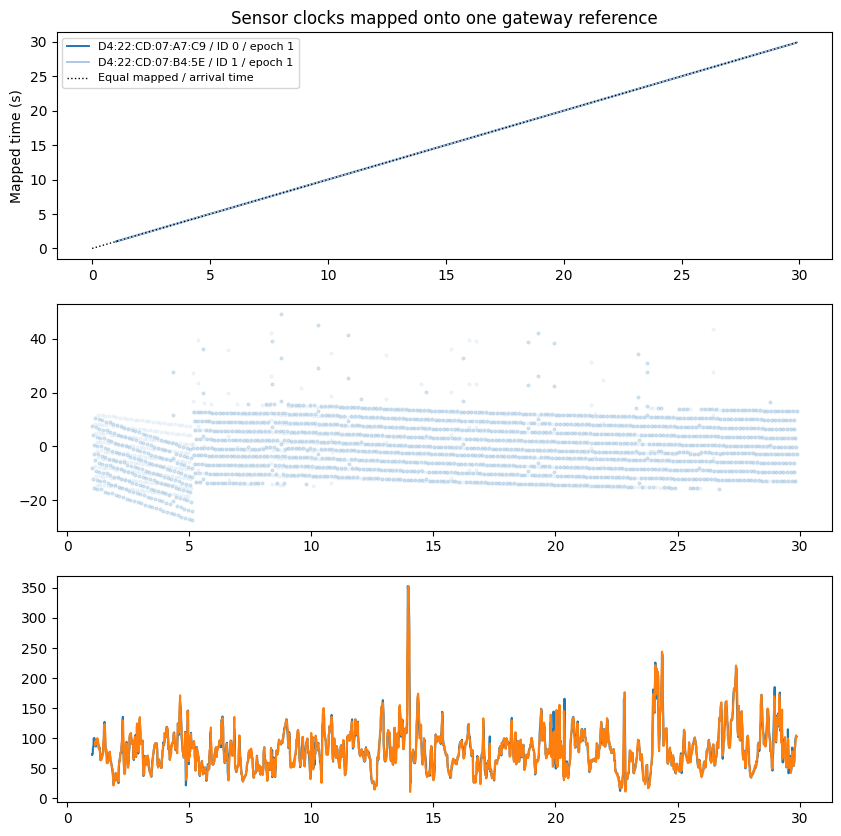

In [57]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# set up a plot
fig, ax = plt.subplots(3)
fig.set_figheight(10)
fig.set_figwidth(10)


end = max((int(row["reference_time_ns"]) - origin) / 1e9 for row in rows)
motion_start, motion_end = 0.0, end
any_acceptance = False

colors = plt.get_cmap("tab20")
for index, (key, device_rows) in enumerate(sorted(groups.items())):
    #print(key, len(device_rows))
    mapped_rows = [row for row in device_rows if row["mapped_timestamp_ns"]]
    #gryo_mag = np.array([row["gyro_z_deg_s"] + row["gyro_x_deg_s"] + row["gyro_y_deg_s"]**2  for row in mapped_rows])   
    if not mapped_rows:
        print(f"Skipping {key}: no mapped timestamps")
        continue
   
    t = np.array([(int(row["reference_time_ns"]) - origin) / 1e9 for row in mapped_rows])
    
    mapped = np.array([(int(row["mapped_timestamp_ns"]) - origin) / 1e9 for row in mapped_rows])
    
    motion_start = min(motion_start, float(mapped.min()))
    motion_end = max(motion_end, float(mapped.max()))

    residual = np.array([(int(row["reference_time_ns"]) - int(row["mapped_timestamp_ns"])) / 1e6  for row in mapped_rows])
    gyro_magnitude_deg_s = []
    for row in mapped_rows:
        gyro = [float(row[f"gyro_{axis}_deg_s"]) for axis in "xyz"] 
        gyro_magnitude_deg_s.append(math.sqrt(sum(value * value for value in gyro)))

    print(len(gyro_magnitude_deg_s))
    
    color = colors(index % 20)
    label = f"{key[0]} / ID {key[1]} / epoch {key[2]}"
    ax[0].plot(t, mapped, color=color, lw=1.4, label=label)
    
    ax[1].scatter(t, residual, color=color, s=4, alpha=.16)
    ax[2].plot(t, gyro_magnitude_deg_s)
    
ax[0].plot([0, end], [0, end], color="black", ls=":", lw=1, label="Equal mapped / arrival time")
ax[0].set(title="Sensor clocks mapped onto one gateway reference", ylabel="Mapped time (s)")
ax[0].legend(loc="upper left", fontsize=8)  